# Local Embedding Model Evaluation (Two Datasets)
This notebook evaluates local embedding models on:
- data_new/SNow_incident_ticket_data.csv
- rchive_data/servicenow_incidents_full.json
Models:
- MPNet baseline (sentence-transformers/all-mpnet-base-v2)
- EmbeddingGemma-300M (google/embeddinggemma-300m)
- V4 MPNet LoRA fine-tune (models/real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20260104_2321)
- text-multilingual-embedding-002 (remote-only, skipped by default)
Notes:
- Description-focused text evaluation.
- Metrics: Spearman, Pearson, ROC-AUC, PR-AUC, F1, precision, recall, accuracy.
- Includes clustering plots and optional semantic kNN graph.


In [16]:
from pathlib import Path
import json
import math
import random
import time
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
def resolve_base_dir():
    cwd = Path.cwd()
    if (cwd / "data_new").exists():
        return cwd
    if (cwd / "nexustism" / "data_new").exists():
        return cwd / "nexustism"
    if (cwd.parent / "data_new").exists():
        return cwd.parent
    return cwd
BASE_DIR = resolve_base_dir()
DATA_DIR = BASE_DIR / "data_new"
ARCHIVE_DIR = BASE_DIR / "archive_data"
MODELS_DIR = BASE_DIR / "models"
RESULTS_DIR = MODELS_DIR / "results"
RANDOM_SEED = 42
USE_DESCRIPTION_ONLY = True
MIN_TEXT_LENGTH = 30
PAIR_SAMPLE_SIZE = 5000
NUM_PAIRS_PER_DATASET = 1200
POS_RATIO = 0.30
HARD_NEG_RATIO = 0.40
POS_TFIDF_THRESHOLD = 0.40
NEG_TFIDF_THRESHOLD = 0.20
HARD_NEG_TFIDF_THRESHOLD = 0.35
DEDUP_TEXTS = True
VAL_RATIO = 0.20
TEST_RATIO = 0.20
RETRIEVAL_ENABLED = True
RETRIEVAL_SAMPLE_SIZE = 2000
RETRIEVAL_KS = (1, 3, 5, 10)
RETRIEVAL_REL_CAP = 50
RERANKER_ENABLED = False
RERANKER_MODEL_ID = "cross-encoder/ms-marco-MiniLM-L-6-v2"
RERANKER_MODEL_PATH = None
RERANK_TOP_K = 50
RERANK_EVAL_KS = (1, 3, 5, 10)
RERANK_MAX_QUERIES = 500
RERANK_BATCH_SIZE = 32
CAUSAL_ENABLED = False
CAUSAL_MODEL_PATH = MODELS_DIR / "causal_classifier" / "causal_crossencoder_v1"
CAUSAL_PAIRS_PATH = BASE_DIR / "data" / "causal_relationship_pairs.json"
CAUSAL_MAX_PAIRS = 2000
CAUSAL_LABEL_MAP = {"causal": 1, "non-causal": 0}
CAUSAL_BATCH_SIZE = 32
MAX_PAIR_ATTEMPTS = 80000
ALLOW_REMOTE_MODELS = False
CLUSTERING_ENABLED = True
CLUSTER_SAMPLE_SIZE = 800
CLUSTER_N_CLUSTERS = 12
KNN_GRAPH_K = 5
DATASETS = [
    {
        "name": "SNow CSV",
        "type": "csv",
        "path": DATA_DIR / "SNow_incident_ticket_data.csv",
        "text_col": "Description",
        "category_col": "Category",
        "use_fixed_pairs": True,
        "pairs_path": DATA_DIR / "fixed_test_pairs.json",
    },
    {
        "name": "ServiceNow JSON",
        "type": "json",
        "path": ARCHIVE_DIR / "servicenow_incidents_full.json",
        "text_col": "description",
        "category_col": "category",
        "use_fixed_pairs": False,
        "pairs_path": None,
        "pos_sim_min": 0.10,
        "pos_sim_max": 0.35,
        "hard_neg_sim_min": 0.30,
    },
]
MODEL_SPECS = [
    {
        "name": "MPNet baseline",
        "type": "hf",
        "model_id": "sentence-transformers/all-mpnet-base-v2",
        "trust_remote_code": False,
    },
    {
        "name": "EmbeddingGemma-300M",
        "type": "hf",
        "model_id": "google/embeddinggemma-300m",
        "trust_remote_code": True,
    },
    {
        "name": "V4 MPNet LoRA",
        "type": "peft",
        "model_path": MODELS_DIR / "real_servicenow_finetuned_mpnet_lora/real_servicenow_v2_20260104_2321",
        "base_model_id": "sentence-transformers/all-mpnet-base-v2",
    },
    {
        "name": "text-multilingual-embedding-002 (remote)",
        "type": "remote",
        "enabled": False,
    },
]
print("Base dir:", BASE_DIR)
print("GPU target: cuda")


Base dir: c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism
GPU target: cuda


In [17]:
import os
def load_token_from_env_file(env_path: Path):
    if not env_path.exists():
        return None
    for raw_line in env_path.read_text(encoding="utf-8", errors="ignore").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.split("=", 1)
        key = key.strip()
        value = value.strip().strip("\"").strip("'")
        if key in {"HUGGINGFACE_TOKEN", "HF_TOKEN", "HUGGINGFACE_HUB_TOKEN"}:
            return value
    return None
def ensure_hf_token():
    token = (
        os.environ.get("HF_TOKEN")
        or os.environ.get("HUGGINGFACE_TOKEN")
        or os.environ.get("HUGGINGFACE_HUB_TOKEN")
    )
    if not token:
        token = load_token_from_env_file(BASE_DIR / ".env")
    if not token:
        print("HF token not found; gated models may fail to download.")
        return None
    os.environ["HF_TOKEN"] = token
    os.environ["HUGGINGFACE_HUB_TOKEN"] = token
    try:
        from huggingface_hub import login
        login(token=token, add_to_git_credential=False)
        print("HF token loaded from .env/env vars.")
    except Exception as exc:
        print(f"HF login failed: {exc}")
    return token
ensure_hf_token()


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF token loaded from .env/env vars.


'***REMOVED***'

In [18]:
import gc
BATCH_SIZE_DEFAULT = 32
BATCH_SIZE_MPS = 8
BATCH_SIZE_GPU_THRESHOLDS = {
    24: 64,
    16: 48,
    12: 32,
    8: 24,
}
def set_all_seeds(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    import torch
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
    print(f"All seeds set to {seed}")
def detect_device():
    import torch
    if torch.cuda.is_available():
        device = "cuda"
        gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
        print(f"Using CUDA: {torch.cuda.get_device_name(0)}")
        print(f"  GPU Memory: {gpu_memory:.2f} GB")
        return device, gpu_memory
    if torch.backends.mps.is_available():
        print("Using Apple MPS")
        return "mps", None
    print("Using CPU (no GPU detected)")
    return "cpu", None
def get_batch_size(device: str, gpu_memory_gb: float = None) -> int:
    if device == "mps":
        return BATCH_SIZE_MPS
    if device == "cuda" and gpu_memory_gb is not None:
        for threshold, batch_size in sorted(BATCH_SIZE_GPU_THRESHOLDS.items(), reverse=True):
            if gpu_memory_gb >= threshold:
                return batch_size
    return BATCH_SIZE_DEFAULT
def cleanup_gpu_memory(device: str = None):
    import torch
    gc.collect()
    if device == "cuda" or (device is None and torch.cuda.is_available()):
        torch.cuda.empty_cache()
        torch.cuda.synchronize()
    elif device == "mps" or (device is None and torch.backends.mps.is_available()):
        torch.mps.empty_cache()
        torch.mps.synchronize()


In [19]:
import re
def clean_text(text: str) -> str:
    if text is None:
        return ""
    text = str(text)
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"^INC\d+\s+", "", text)
    return text
def load_json_with_fallback(path: Path):
    raw = Path(path).read_bytes()
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            return json.loads(raw.decode(enc))
        except UnicodeDecodeError:
            continue
    return json.loads(raw.decode("utf-8", errors="replace"))
def load_dataset_records(dataset):
    if dataset["type"] == "csv":
        df = pd.read_csv(dataset["path"], encoding="utf-8", on_bad_lines="skip")
        text_col = dataset["text_col"]
        categories = df[dataset["category_col"]].fillna("") if dataset.get("category_col") in df else None
        texts = df[text_col].fillna("").astype(str).tolist()
    elif dataset["type"] == "json":
        rows = load_json_with_fallback(dataset["path"])
        text_col = dataset["text_col"]
        texts = [str(row.get(text_col, "")) for row in rows]
        categories = [row.get(dataset.get("category_col", ""), "") for row in rows] if dataset.get("category_col") else None
    else:
        raise ValueError(f"Unsupported dataset type: {dataset['type']}")
    cleaned = []
    cleaned_categories = []
    for idx, text in enumerate(texts):
        cleaned_text = clean_text(text)
        if len(cleaned_text) < MIN_TEXT_LENGTH:
            continue
        cleaned.append(cleaned_text)
        if categories is not None:
            cleaned_categories.append(clean_text(categories[idx]))
    print(f"Loaded {len(cleaned):,} texts from {dataset['name']}")
    return cleaned, cleaned_categories if categories is not None else None


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
def load_fixed_pairs(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    texts1 = [clean_text(t) for t in data["texts1"]]
    texts2 = [clean_text(t) for t in data["texts2"]]
    labels = np.array(data["labels"])
    categories1 = data.get("categories1")
    categories2 = data.get("categories2")
    if categories1 is not None:
        categories1 = [clean_text(c) for c in categories1]
    if categories2 is not None:
        categories2 = [clean_text(c) for c in categories2]
    return texts1, texts2, labels, categories1, categories2
def generate_pairs(texts, categories=None, pos_sim_min=None, pos_sim_max=None, hard_neg_sim_min=None):
    rng = np.random.default_rng(RANDOM_SEED)
    pos_min = POS_TFIDF_THRESHOLD if pos_sim_min is None else pos_sim_min
    pos_max = pos_sim_max
    hard_min = HARD_NEG_TFIDF_THRESHOLD if hard_neg_sim_min is None else hard_neg_sim_min
    def normalize_for_dedup(text):
        return clean_text(text).lower()
    if DEDUP_TEXTS:
        seen = set()
        dedup_texts = []
        dedup_categories = [] if categories is not None else None
        for idx, text in enumerate(texts):
            key = normalize_for_dedup(text)
            if not key or key in seen:
                continue
            seen.add(key)
            dedup_texts.append(text)
            if categories is not None:
                dedup_categories.append(categories[idx])
        dropped = len(texts) - len(dedup_texts)
        if dropped:
            print(f'Deduplicated {dropped:,} texts; {len(dedup_texts):,} remain')
        texts = dedup_texts
        if categories is not None:
            categories = dedup_categories
    total_texts = len(texts)
    if total_texts < 2:
        raise ValueError('Not enough texts to generate pairs.')
    if total_texts > PAIR_SAMPLE_SIZE:
        sample_idx = rng.choice(total_texts, size=PAIR_SAMPLE_SIZE, replace=False)
        texts = [texts[i] for i in sample_idx]
        if categories is not None:
            categories = [categories[i] for i in sample_idx]
        print(f'Pair sampling: reduced to {len(texts):,} texts')
    use_categories = categories is not None and any(c for c in categories)
    vectorizer = TfidfVectorizer(max_features=15000, stop_words='english', ngram_range=(1, 2))
    tfidf = vectorizer.fit_transform(texts)
    pos_target = int(NUM_PAIRS_PER_DATASET * POS_RATIO)
    hard_target = int(NUM_PAIRS_PER_DATASET * HARD_NEG_RATIO)
    easy_target = NUM_PAIRS_PER_DATASET - pos_target - hard_target
    pairs = []
    attempts = 0
    def similarity(i, j):
        return float((tfidf[i] @ tfidf[j].T).toarray()[0][0])
    def make_pair(i, j, label):
        cat_a = categories[i] if categories is not None else None
        cat_b = categories[j] if categories is not None else None
        return (texts[i], texts[j], label, cat_a, cat_b)
    def is_same_category(i, j):
        if not use_categories:
            return False
        return bool(categories[i]) and bool(categories[j]) and categories[i] == categories[j]
    while attempts < MAX_PAIR_ATTEMPTS and len(pairs) < NUM_PAIRS_PER_DATASET:
        attempts += 1
        i, j = rng.integers(0, len(texts), size=2)
        if i == j or texts[i] == texts[j]:
            continue
        sim = similarity(i, j)
        same_category = is_same_category(i, j)
        if len(pairs) < pos_target:
            if (use_categories and same_category and sim >= pos_min) or (not use_categories and sim >= pos_min):
                if pos_max is None or sim <= pos_max:
                    pairs.append(make_pair(i, j, 1))
            continue
        if len(pairs) < pos_target + hard_target:
            if use_categories:
                if (not same_category) and sim >= hard_min:
                    pairs.append(make_pair(i, j, 0))
            elif sim <= NEG_TFIDF_THRESHOLD:
                pairs.append(make_pair(i, j, 0))
            continue
        if use_categories:
            if (not same_category) and sim <= NEG_TFIDF_THRESHOLD:
                pairs.append(make_pair(i, j, 0))
        elif sim <= NEG_TFIDF_THRESHOLD:
            pairs.append(make_pair(i, j, 0))
    if len(pairs) == 0:
        print('No pairs generated; relaxing thresholds and retrying.')
        relaxed_pos = max(0.15, pos_min * 0.6)
        relaxed_neg = min(0.35, NEG_TFIDF_THRESHOLD * 1.5)
        relaxed_hard = max(relaxed_neg, hard_min * 0.8)
        attempts = 0
        while attempts < MAX_PAIR_ATTEMPTS and len(pairs) < NUM_PAIRS_PER_DATASET:
            attempts += 1
            i, j = rng.integers(0, len(texts), size=2)
            if i == j or texts[i] == texts[j]:
                continue
            sim = similarity(i, j)
            same_category = is_same_category(i, j)
            if len(pairs) < pos_target:
                if (use_categories and same_category and sim >= relaxed_pos) or (not use_categories and sim >= relaxed_pos):
                    if pos_max is None or sim <= pos_max:
                        pairs.append(make_pair(i, j, 1))
                continue
            if len(pairs) < pos_target + hard_target:
                if use_categories:
                    if (not same_category) and sim >= relaxed_hard:
                        pairs.append(make_pair(i, j, 0))
                elif sim <= relaxed_neg:
                    pairs.append(make_pair(i, j, 0))
                continue
            if use_categories:
                if (not same_category) and sim <= relaxed_neg:
                    pairs.append(make_pair(i, j, 0))
            elif sim <= relaxed_neg:
                pairs.append(make_pair(i, j, 0))
        if len(pairs) == 0 and use_categories:
            print('Fallback to category-only pairing.')
            category_to_indices = {}
            for idx, cat in enumerate(categories):
                if not cat:
                    continue
                category_to_indices.setdefault(cat, []).append(idx)
            valid_categories = [c for c, idxs in category_to_indices.items() if len(idxs) > 1]
            attempts = 0
            while attempts < MAX_PAIR_ATTEMPTS and len(pairs) < NUM_PAIRS_PER_DATASET and valid_categories:
                attempts += 1
                if len(pairs) < pos_target:
                    cat = rng.choice(valid_categories)
                    i, j = rng.choice(category_to_indices[cat], size=2, replace=False)
                    if texts[i] != texts[j]:
                        sim = similarity(i, j)
                        if pos_max is None or sim <= pos_max:
                            pairs.append(make_pair(i, j, 1))
                    continue
                if len(valid_categories) < 2:
                    break
                cat_a, cat_b = rng.choice(valid_categories, size=2, replace=False)
                i = rng.choice(category_to_indices[cat_a])
                j = rng.choice(category_to_indices[cat_b])
                if texts[i] != texts[j]:
                    pairs.append(make_pair(i, j, 0))
        if len(pairs) == 0:
            print('Fallback to sampled similarity pairs.')
            candidates = []
            attempts = 0
            target = max(pos_target, easy_target)
            while attempts < MAX_PAIR_ATTEMPTS and len(candidates) < target * 5:
                attempts += 1
                i, j = rng.integers(0, len(texts), size=2)
                if i == j or texts[i] == texts[j]:
                    continue
                sim = similarity(i, j)
                candidates.append((sim, i, j))
            if candidates:
                candidates.sort(key=lambda x: x[0], reverse=True)
                for sim, i, j in candidates:
                    if pos_max is not None and sim > pos_max:
                        continue
                    pairs.append(make_pair(i, j, 1))
                    if len(pairs) >= max(1, pos_target):
                        break
                candidates.sort(key=lambda x: x[0])
                for sim, i, j in candidates[:max(1, easy_target)]:
                    pairs.append(make_pair(i, j, 0))
        if len(pairs) == 0:
            raise ValueError('No pairs generated; check thresholds or dataset size.')
    labels = np.array([p[2] for p in pairs])
    if labels.sum() == 0 or labels.sum() == len(labels):
        print('Warning: only one class in generated pairs; adding fallback pairs.')
        def sample_candidates(sample_count):
            candidates = []
            local_attempts = 0
            while local_attempts < MAX_PAIR_ATTEMPTS and len(candidates) < sample_count:
                local_attempts += 1
                i, j = rng.integers(0, len(texts), size=2)
                if i == j or texts[i] == texts[j]:
                    continue
                sim = similarity(i, j)
                candidates.append((sim, i, j))
            return candidates
        if labels.sum() == 0:
            candidates = sample_candidates(pos_target * 5)
            candidates.sort(key=lambda x: x[0], reverse=True)
            added = 0
            for sim, i, j in candidates:
                if use_categories and not is_same_category(i, j):
                    continue
                if pos_max is not None and sim > pos_max:
                    continue
                pairs.append(make_pair(i, j, 1))
                added += 1
                if added >= max(1, pos_target):
                    break
        if labels.sum() == len(labels):
            candidates = sample_candidates(easy_target * 5)
            candidates.sort(key=lambda x: x[0])
            added = 0
            for sim, i, j in candidates:
                if use_categories and is_same_category(i, j):
                    continue
                pairs.append(make_pair(i, j, 0))
                added += 1
                if added >= max(1, easy_target):
                    break
    rng.shuffle(pairs)
    pairs = pairs[:NUM_PAIRS_PER_DATASET]
    texts1 = [p[0] for p in pairs]
    texts2 = [p[1] for p in pairs]
    labels = np.array([p[2] for p in pairs])
    categories1 = [p[3] for p in pairs]
    categories2 = [p[4] for p in pairs]
    if len(pairs) < NUM_PAIRS_PER_DATASET:
        print(f'Warning: only generated {len(pairs)} pairs (attempts: {attempts})')
    return texts1, texts2, labels, categories1, categories2
def validate_pairs(texts1, texts2, labels):
    assert len(texts1) == len(texts2) == len(labels), "Mismatched pair lengths"
    pos = labels.sum()
    neg = len(labels) - pos
    print(f"Pairs: {len(labels)}, Pos: {pos} ({pos/len(labels)*100:.1f}%), Neg: {neg} ({neg/len(labels)*100:.1f}%)")
def stratified_split_indices(labels, val_ratio, test_ratio, seed):
    labels = np.array(labels)
    rng = np.random.default_rng(seed)
    pos_idx = np.where(labels == 1)[0]
    neg_idx = np.where(labels == 0)[0]
    rng.shuffle(pos_idx)
    rng.shuffle(neg_idx)
    def split(idx):
        if len(idx) < 2:
            return np.array([], dtype=int), np.array([], dtype=int)
        val_size = max(1, int(round(len(idx) * val_ratio)))
        test_size = max(1, int(round(len(idx) * test_ratio)))
        if val_size + test_size >= len(idx):
            val_size = max(1, len(idx) // 3)
            test_size = max(1, len(idx) // 3) if len(idx) - val_size > 0 else 0
        return idx[:val_size], idx[val_size:val_size + test_size]
    pos_val, pos_test = split(pos_idx)
    neg_val, neg_test = split(neg_idx)
    val_idx = np.concatenate([pos_val, neg_val])
    test_idx = np.concatenate([pos_test, neg_test])
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)
    return {"val_idx": val_idx, "test_idx": test_idx}
def build_retrieval_sample(texts, categories, sample_size, seed):
    if categories is None:
        return None
    category_to_indices = {}
    for idx, cat in enumerate(categories):
        if not cat:
            continue
        category_to_indices.setdefault(cat, []).append(idx)
    eligible = []
    for idxs in category_to_indices.values():
        if len(idxs) > 1:
            eligible.extend(idxs)
    if len(eligible) < 2:
        return None
    rng = np.random.default_rng(seed)
    if len(eligible) > sample_size:
        chosen = rng.choice(eligible, size=sample_size, replace=False)
    else:
        chosen = np.array(eligible)
    sample_texts = [texts[i] for i in chosen]
    sample_categories = [categories[i] for i in chosen]
    return {"texts": sample_texts, "categories": sample_categories}
def compute_retrieval_metrics(embeddings, categories, ks, rel_cap=None, seed=RANDOM_SEED):
    if len(embeddings) < 2:
        return {}
    emb = np.array(embeddings, dtype=np.float32)
    norms = np.linalg.norm(emb, axis=1, keepdims=True)
    emb = emb / np.clip(norms, 1e-12, None)
    sim = emb @ emb.T
    np.fill_diagonal(sim, -np.inf)
    categories = np.array(categories)
    max_k = max(ks)
    rng = np.random.default_rng(seed)
    recalls = {k: [] for k in ks}
    hits_at = {k: [] for k in ks}
    ndcgs = {k: [] for k in ks}
    mrrs = []
    for i in range(len(categories)):
        rel_idx = np.where(categories == categories[i])[0]
        rel_idx = rel_idx[rel_idx != i]
        if rel_idx.size == 0:
            continue
        if rel_cap and rel_idx.size > rel_cap:
            rel_idx = rng.choice(rel_idx, size=rel_cap, replace=False)
        ranked = np.argsort(-sim[i])
        for k in ks:
            topk = ranked[:k]
            hits = np.intersect1d(topk, rel_idx).size
            recalls[k].append(hits / rel_idx.size)
            hits_at[k].append(1.0 if hits > 0 else 0.0)
            gains = np.isin(topk, rel_idx).astype(int)
            if gains.size:
                dcg = np.sum(gains / np.log2(np.arange(2, gains.size + 2)))
                ideal_hits = min(rel_idx.size, k)
                idcg = np.sum(1 / np.log2(np.arange(2, ideal_hits + 2)))
                ndcgs[k].append(dcg / idcg if idcg > 0 else 0.0)
        top_max = ranked[:max_k]
        hit_positions = np.where(np.isin(top_max, rel_idx))[0]
        if hit_positions.size:
            mrrs.append(1.0 / (hit_positions[0] + 1))
        else:
            mrrs.append(0.0)
    metrics = {}
    for k in ks:
        metrics[f"recall@{k}"] = float(np.mean(recalls[k])) if recalls[k] else 0.0
        metrics[f"hit@{k}"] = float(np.mean(hits_at[k])) if hits_at[k] else 0.0
        metrics[f"ndcg@{k}"] = float(np.mean(ndcgs[k])) if ndcgs[k] else 0.0
    metrics[f"mrr@{max_k}"] = float(np.mean(mrrs)) if mrrs else 0.0
    metrics["retrieval_queries"] = int(len(mrrs))
    return metrics
def compute_rerank_metrics(embeddings, texts, categories, reranker, top_k, ks, rel_cap=None, max_queries=None, batch_size=32, seed=RANDOM_SEED):
    if len(embeddings) < 2:
        return {}
    emb = np.array(embeddings, dtype=np.float32)
    norms = np.linalg.norm(emb, axis=1, keepdims=True)
    emb = emb / np.clip(norms, 1e-12, None)
    sim = emb @ emb.T
    np.fill_diagonal(sim, -np.inf)
    categories = np.array(categories)
    rng = np.random.default_rng(seed)
    query_indices = np.arange(len(categories))
    if max_queries and len(query_indices) > max_queries:
        query_indices = rng.choice(query_indices, size=max_queries, replace=False)
    max_k = max(ks)
    recalls = {k: [] for k in ks}
    hits_at = {k: [] for k in ks}
    ndcgs = {k: [] for k in ks}
    mrrs = []
    total_queries = 0
    for i in query_indices:
        rel_idx = np.where(categories == categories[i])[0]
        rel_idx = rel_idx[rel_idx != i]
        if rel_idx.size == 0:
            continue
        if rel_cap and rel_idx.size > rel_cap:
            rel_idx = rng.choice(rel_idx, size=rel_cap, replace=False)
        ranked = np.argsort(-sim[i])
        topk = ranked[:top_k]
        pair_texts = [(texts[i], texts[j]) for j in topk]
        scores = reranker.predict(pair_texts, batch_size=batch_size, show_progress_bar=False)
        scores = np.array(scores).reshape(-1)
        reranked = topk[np.argsort(-scores)]
        total_queries += 1
        for k in ks:
            topk_r = reranked[:k]
            hits = np.intersect1d(topk_r, rel_idx).size
            recalls[k].append(hits / rel_idx.size)
            hits_at[k].append(1.0 if hits > 0 else 0.0)
            gains = np.isin(topk_r, rel_idx).astype(int)
            if gains.size:
                dcg = np.sum(gains / np.log2(np.arange(2, gains.size + 2)))
                ideal_hits = min(rel_idx.size, k)
                idcg = np.sum(1 / np.log2(np.arange(2, ideal_hits + 2)))
                ndcgs[k].append(dcg / idcg if idcg > 0 else 0.0)
        top_max = reranked[:max_k]
        hit_positions = np.where(np.isin(top_max, rel_idx))[0]
        if hit_positions.size:
            mrrs.append(1.0 / (hit_positions[0] + 1))
        else:
            mrrs.append(0.0)
    metrics = {}
    for k in ks:
        metrics[f"recall@{k}"] = float(np.mean(recalls[k])) if recalls[k] else 0.0
        metrics[f"hit@{k}"] = float(np.mean(hits_at[k])) if hits_at[k] else 0.0
        metrics[f"ndcg@{k}"] = float(np.mean(ndcgs[k])) if ndcgs[k] else 0.0
    metrics[f"mrr@{max_k}"] = float(np.mean(mrrs)) if mrrs else 0.0
    metrics["rerank_queries"] = int(total_queries)
    return metrics


In [21]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix,
)
from scipy.stats import spearmanr, pearsonr
def find_best_threshold(labels, scores, num_steps=200):
    thresholds = np.linspace(scores.min(), scores.max(), num_steps)
    best_f1 = -1
    best_threshold = thresholds[0]
    for t in thresholds:
        preds = (scores >= t).astype(int)
        f1 = f1_score(labels, preds, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = t
    return float(best_threshold), float(best_f1)
def compute_metrics(labels, scores, threshold):
    preds = (scores >= threshold).astype(int)
    pos_scores = scores[labels == 1]
    neg_scores = scores[labels == 0]
    has_label_var = len(set(labels)) > 1
    has_score_var = len(set(scores)) > 1
    spearman_val = spearmanr(labels, scores)[0] if has_label_var and has_score_var else 0.0
    pearson_val = pearsonr(labels, scores)[0] if has_label_var and has_score_var else 0.0
    return {
        "spearman": spearman_val,
        "pearson": pearson_val,
        "roc_auc": roc_auc_score(labels, scores) if has_label_var else 0.0,
        "pr_auc": average_precision_score(labels, scores) if has_label_var else 0.0,
        "f1": f1_score(labels, preds, zero_division=0),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "accuracy": accuracy_score(labels, preds),
        "mean_pos": float(np.mean(pos_scores)) if len(pos_scores) else 0.0,
        "mean_neg": float(np.mean(neg_scores)) if len(neg_scores) else 0.0,
        "separation": float(np.mean(pos_scores) - np.mean(neg_scores)) if len(pos_scores) and len(neg_scores) else 0.0,
    }
def compute_confusion(labels, scores, threshold):
    preds = (scores >= threshold).astype(int)
    return confusion_matrix(labels, preds, labels=[0, 1])


In [22]:
from sentence_transformers import SentenceTransformer, CrossEncoder
def load_hf_model(model_id, trust_remote_code, device):
    return SentenceTransformer(model_id, device=device, trust_remote_code=trust_remote_code)
def load_peft_model(model_path, base_model_id, device):
    from peft import PeftModel
    base_model = SentenceTransformer(base_model_id, device=device)
    base_model[0].auto_model = PeftModel.from_pretrained(base_model[0].auto_model, str(model_path))
    return base_model


In [23]:
from sklearn.metrics.pairwise import cosine_similarity
class ModelEvaluator:
    def __init__(self):
        self.results = {}
    def evaluate(self, model, model_name, texts1, texts2, labels, batch_size, device, split_info=None, retrieval_data=None, reranker=None):
        print(f"\n{'='*70}\nEvaluating: {model_name}\n{'='*70}")
        emb1 = model.encode(texts1, batch_size=batch_size, show_progress_bar=True, device=device)
        emb2 = model.encode(texts2, batch_size=batch_size, show_progress_bar=True, device=device)
        scores = np.array([cosine_similarity([emb1[i]], [emb2[i]])[0, 0] for i in range(len(emb1))])
        if split_info and len(split_info.get("val_idx", [])) and len(split_info.get("test_idx", [])):
            val_idx = split_info["val_idx"]
            test_idx = split_info["test_idx"]
            val_scores = scores[val_idx]
            val_labels = labels[val_idx]
            test_scores = scores[test_idx]
            test_labels = labels[test_idx]
            threshold, best_f1 = find_best_threshold(val_labels, val_scores)
            metrics = compute_metrics(test_labels, test_scores, threshold)
            metrics["val_best_threshold"] = threshold
            metrics["val_best_f1"] = best_f1
            metrics["val_size"] = int(len(val_idx))
            metrics["test_size"] = int(len(test_idx))
            metrics["confusion_matrix"] = compute_confusion(test_labels, test_scores, threshold).tolist()
        else:
            threshold, best_f1 = find_best_threshold(labels, scores)
            metrics = compute_metrics(labels, scores, threshold)
            metrics["best_threshold"] = threshold
            metrics["best_f1"] = best_f1
            metrics["val_size"] = 0
            metrics["test_size"] = int(len(labels))
            metrics["confusion_matrix"] = compute_confusion(labels, scores, threshold).tolist()
        if retrieval_data and retrieval_data.get("texts"):
            retrieval_emb = model.encode(retrieval_data["texts"], batch_size=batch_size, show_progress_bar=True, device=device)
            retrieval_metrics = compute_retrieval_metrics(
                retrieval_emb,
                retrieval_data["categories"],
                RETRIEVAL_KS,
                rel_cap=RETRIEVAL_REL_CAP,
            )
            for key, value in retrieval_metrics.items():
                metrics[f"retrieval_{key}"] = value
            if reranker is not None:
                rerank_metrics = compute_rerank_metrics(
                    retrieval_emb,
                    retrieval_data["texts"],
                    retrieval_data["categories"],
                    reranker,
                    RERANK_TOP_K,
                    RERANK_EVAL_KS,
                    rel_cap=RETRIEVAL_REL_CAP,
                    max_queries=RERANK_MAX_QUERIES,
                    batch_size=RERANK_BATCH_SIZE,
                )
                for key, value in rerank_metrics.items():
                    metrics[f"rerank_{key}"] = value
        self.results[model_name] = {
            "metrics": metrics,
            "scores": scores,
            "labels": labels,
            "embeddings1": emb1,
            "embeddings2": emb2,
        }
        print(f"Spearman: {metrics['spearman']:.4f} | ROC-AUC: {metrics['roc_auc']:.4f} | F1: {metrics['f1']:.4f}")
        return metrics


In [24]:
set_all_seeds(RANDOM_SEED)
raw_texts_by_dataset = {}
pairs_by_dataset = {}
retrieval_by_dataset = {}
for dataset in DATASETS:
    texts, categories = load_dataset_records(dataset)
    raw_texts_by_dataset[dataset["name"]] = (texts, categories)
    if RETRIEVAL_ENABLED:
        retrieval_by_dataset[dataset["name"]] = build_retrieval_sample(texts, categories, RETRIEVAL_SAMPLE_SIZE, RANDOM_SEED)
    else:
        retrieval_by_dataset[dataset["name"]] = None
    if dataset.get("use_fixed_pairs") and dataset.get("pairs_path") and dataset["pairs_path"].exists():
        print(f"Loading fixed pairs for {dataset['name']}")
        texts1, texts2, labels, cat1, cat2 = load_fixed_pairs(dataset["pairs_path"])
    else:
        print(f"Generating pairs for {dataset['name']}")
        texts1, texts2, labels, cat1, cat2 = generate_pairs(
            texts,
            categories,
            pos_sim_min=dataset.get("pos_sim_min"),
            pos_sim_max=dataset.get("pos_sim_max"),
            hard_neg_sim_min=dataset.get("hard_neg_sim_min"),
        )
    validate_pairs(texts1, texts2, labels)
    split_info = stratified_split_indices(labels, VAL_RATIO, TEST_RATIO, RANDOM_SEED)
    pairs_by_dataset[dataset["name"]] = {
        "texts1": texts1,
        "texts2": texts2,
        "labels": labels,
        "categories1": cat1,
        "categories2": cat2,
        "split": split_info,
    }


All seeds set to 42
Loaded 10,383 texts from SNow CSV
Loading fixed pairs for SNow CSV
Pairs: 1000, Pos: 500 (50.0%), Neg: 500 (50.0%)
Loaded 71 texts from ServiceNow JSON
Generating pairs for ServiceNow JSON
Deduplicated 1 texts; 70 remain
Pairs: 438, Pos: 360 (82.2%), Neg: 78 (17.8%)


In [25]:
device, gpu_mem = detect_device()
batch_size = get_batch_size(device, gpu_mem)
print(f"Batch size: {batch_size}")
reranker = None
if RERANKER_ENABLED:
    if RERANKER_MODEL_PATH and Path(RERANKER_MODEL_PATH).exists():
        reranker_id = str(RERANKER_MODEL_PATH)
    else:
        reranker_id = RERANKER_MODEL_ID
    if reranker_id:
        reranker = CrossEncoder(reranker_id, device=device)
        print(f"Loaded reranker: {reranker_id}")
    else:
        print("Reranker enabled but no model configured; skipping rerank evaluation")
spec_by_name = {spec["name"]: spec for spec in MODEL_SPECS}
results_by_dataset = {}
for dataset_name, pair_data in pairs_by_dataset.items():
    evaluator = ModelEvaluator()
    print(f"\n{'#'*80}\nDATASET: {dataset_name}\n{'#'*80}")
    for spec in MODEL_SPECS:
        if spec["type"] == "remote" and not ALLOW_REMOTE_MODELS:
            print(f"Skipping remote model: {spec['name']} (local-only mode)")
            continue
        if spec["type"] == "peft":
            model_path = spec["model_path"]
            if not model_path.exists():
                print(f"Skipping missing model: {model_path}")
                continue
            model = load_peft_model(model_path, spec["base_model_id"], device)
        elif spec["type"] == "hf":
            model = load_hf_model(spec["model_id"], spec.get("trust_remote_code", False), device)
        else:
            print(f"Skipping unsupported model type: {spec['name']}")
            continue
        evaluator.evaluate(
            model=model,
            model_name=spec["name"],
            texts1=pair_data["texts1"],
            texts2=pair_data["texts2"],
            labels=pair_data["labels"],
            split_info=pair_data.get("split"),
            retrieval_data=retrieval_by_dataset.get(dataset_name),
            reranker=reranker,
            batch_size=batch_size,
            device=device,
        )
        del model
        cleanup_gpu_memory(device)
    results_by_dataset[dataset_name] = evaluator.results


Using CUDA: NVIDIA GeForce RTX 5090
  GPU Memory: 31.84 GB
Batch size: 64

################################################################################
DATASET: SNow CSV
################################################################################

Evaluating: MPNet baseline


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Spearman: 0.3989 | ROC-AUC: 0.7303 | F1: 0.6612

Evaluating: EmbeddingGemma-300M


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

... (15 outputs left out)

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Spearman: -0.2090 | ROC-AUC: 0.3438 | F1: 0.9000
Skipping remote model: text-multilingual-embedding-002 (remote) (local-only mode)


In [26]:
metrics_tables = {}
for dataset_name, results in results_by_dataset.items():
    rows = {}
    for model_name, result in results.items():
        rows[model_name] = result["metrics"]
    df = pd.DataFrame(rows).T.sort_values("spearman", ascending=False)
    metrics_tables[dataset_name] = df
    print(f"\n{'='*80}\nSUMMARY: {dataset_name}\n{'='*80}")
    display(df)



SUMMARY: SNow CSV


,spearman,pearson,roc_auc,pr_auc,f1,precision,recall,accuracy,mean_pos,mean_neg,...,retrieval_hit@3,retrieval_ndcg@3,retrieval_recall@5,retrieval_hit@5,retrieval_ndcg@5,retrieval_recall@10,retrieval_hit@10,retrieval_ndcg@10,retrieval_mrr@10,retrieval_retrieval_queries
MPNet baseline,0.398898,0.449006,0.7303,0.793136,0.661157,0.56338,0.8,0.59,0.471555,0.300169,...,0.086,0.035157,0.00331,0.1255,0.033807,0.00674,0.2365,0.033829,0.082156,2000
V4 MPNet LoRA,0.376035,0.443486,0.7171,0.781934,0.663551,0.622807,0.71,0.64,0.511833,0.309614,...,0.083,0.033654,0.00344,0.1265,0.033684,0.0066,0.2355,0.032877,0.078309,2000
EmbeddingGemma-300M,0.302767,0.386516,0.6748,0.760792,0.630037,0.49711,0.86,0.495,0.485209,0.366523,...,0.092,0.037791,0.00359,0.1335,0.035741,0.00651,0.2275,0.033089,0.083275,2000



SUMMARY: ServiceNow JSON


,spearman,pearson,roc_auc,pr_auc,f1,precision,recall,accuracy,mean_pos,mean_neg,...,retrieval_hit@3,retrieval_ndcg@3,retrieval_recall@5,retrieval_hit@5,retrieval_ndcg@5,retrieval_recall@10,retrieval_hit@10,retrieval_ndcg@10,retrieval_mrr@10,retrieval_retrieval_queries
EmbeddingGemma-300M,-0.197347,-0.217902,0.352431,0.735922,0.9,0.818182,1.0,0.818182,0.601947,0.670966,...,0.776119,0.471691,0.101493,0.850746,0.447653,0.179561,0.925373,0.417484,0.639588,67
MPNet baseline,-0.208922,-0.225629,0.34375,0.743544,0.9,0.818182,1.0,0.818182,0.451004,0.559934,...,0.716418,0.480529,0.10029,0.820896,0.467305,0.19233,0.925373,0.455143,0.5966,67
V4 MPNet LoRA,-0.208954,-0.249247,0.34375,0.743451,0.9,0.818182,1.0,0.818182,0.438911,0.563487,...,0.731343,0.475193,0.10029,0.820896,0.469545,0.187438,0.925373,0.44577,0.595896,67


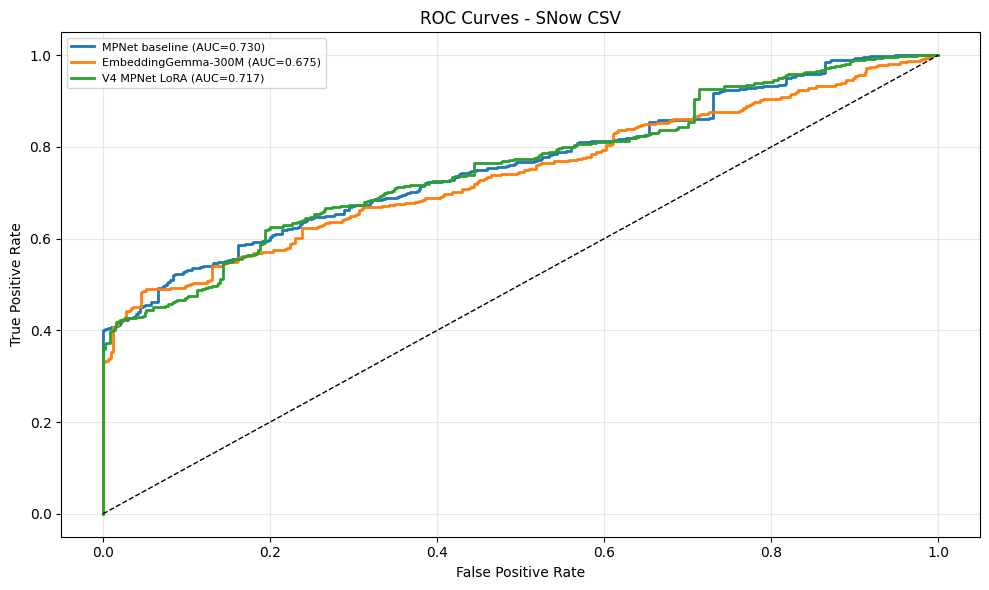

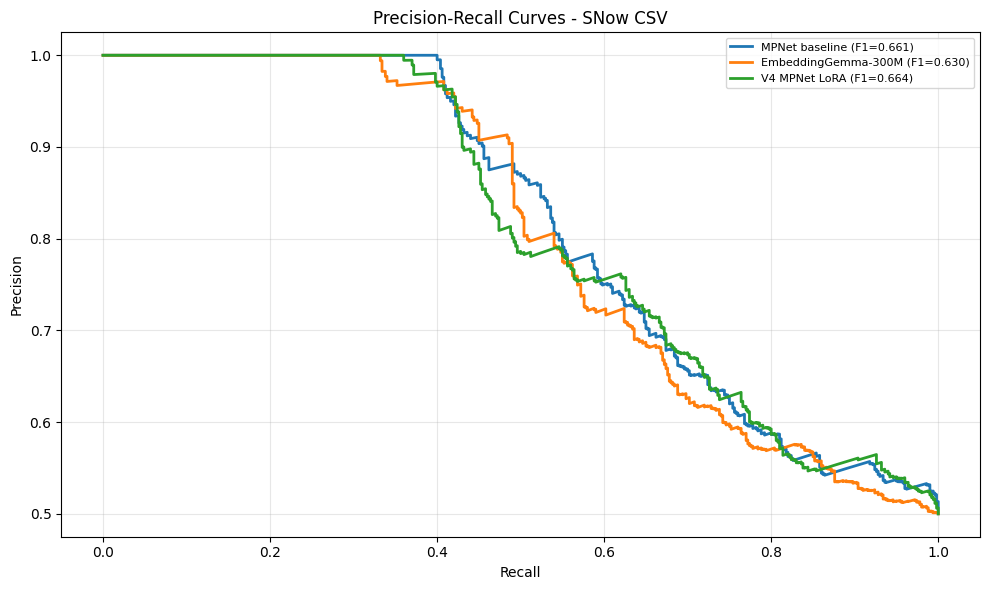

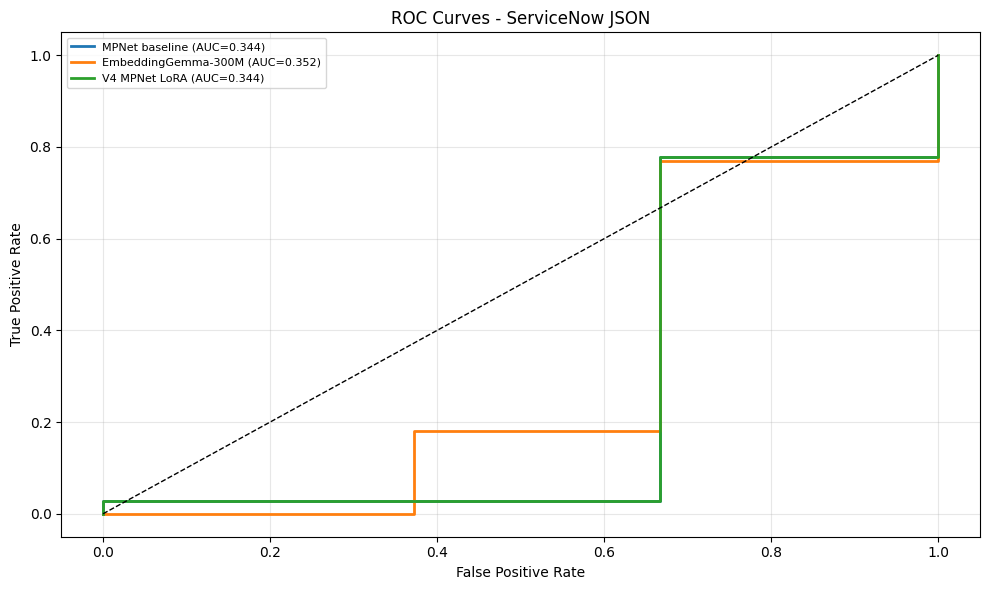

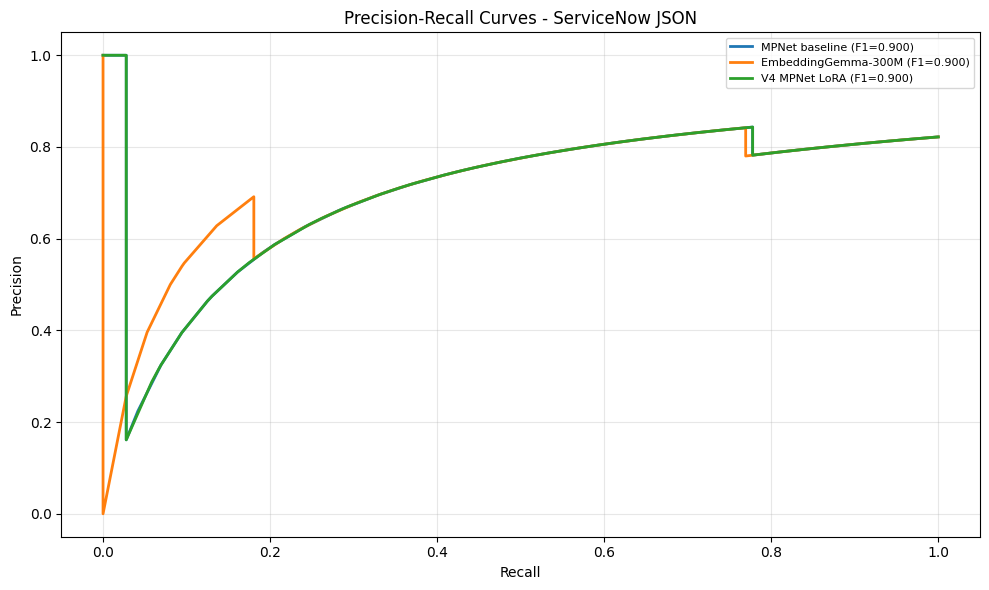

In [27]:
from sklearn.metrics import roc_curve, precision_recall_curve
for dataset_name, results in results_by_dataset.items():
    if not results:
        continue
    # ROC curves
    fig, ax = plt.subplots(figsize=(10, 6))
    for model_name, result in results.items():
        fpr, tpr, _ = roc_curve(result["labels"], result["scores"])
        auc = result["metrics"]["roc_auc"]
        ax.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.3f})", linewidth=2)
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"ROC Curves - {dataset_name}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    # PR curves
    fig, ax = plt.subplots(figsize=(10, 6))
    for model_name, result in results.items():
        precision, recall, _ = precision_recall_curve(result["labels"], result["scores"])
        f1 = result["metrics"]["f1"]
        ax.plot(recall, precision, label=f"{model_name} (F1={f1:.3f})", linewidth=2)
    ax.set_title(f"Precision-Recall Curves - {dataset_name}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


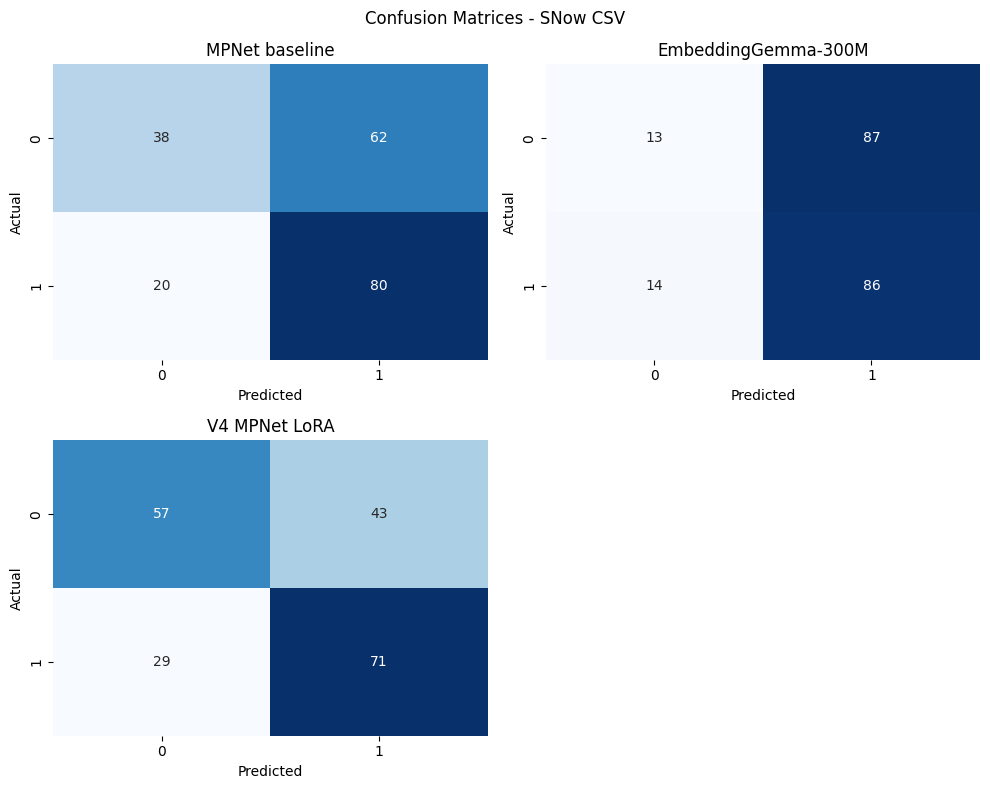

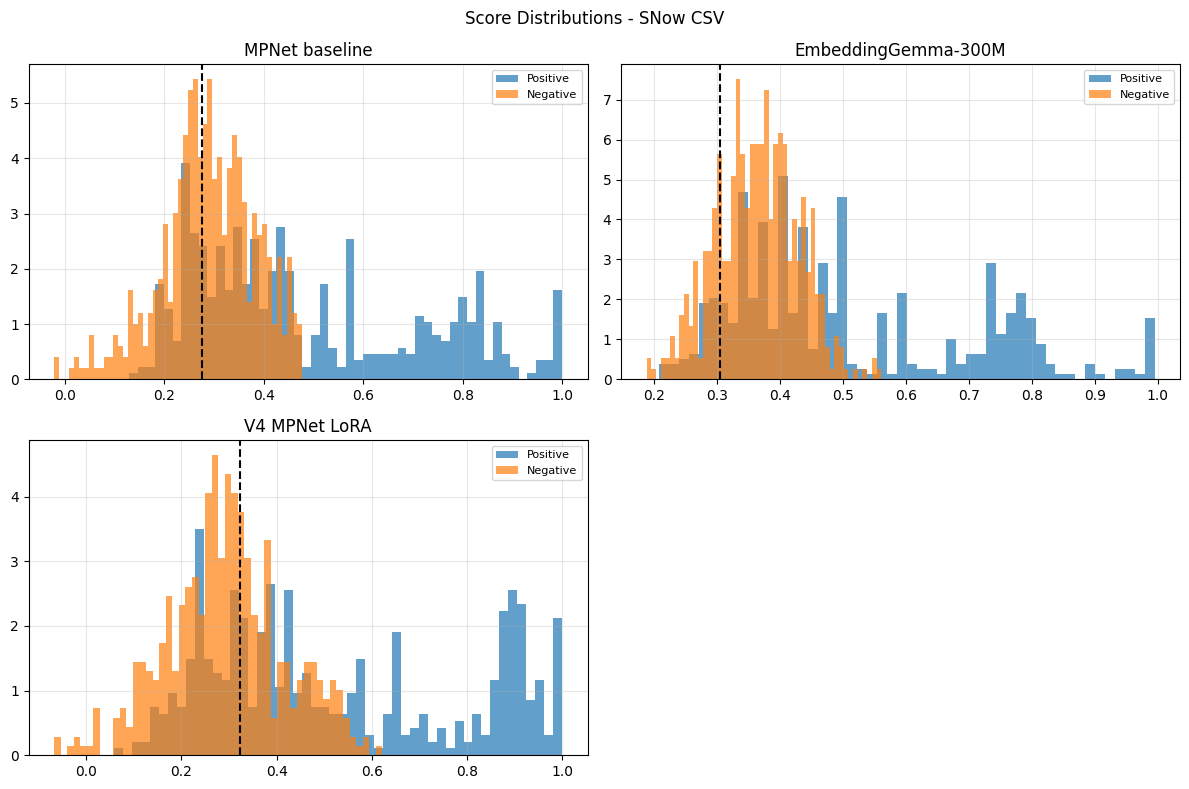

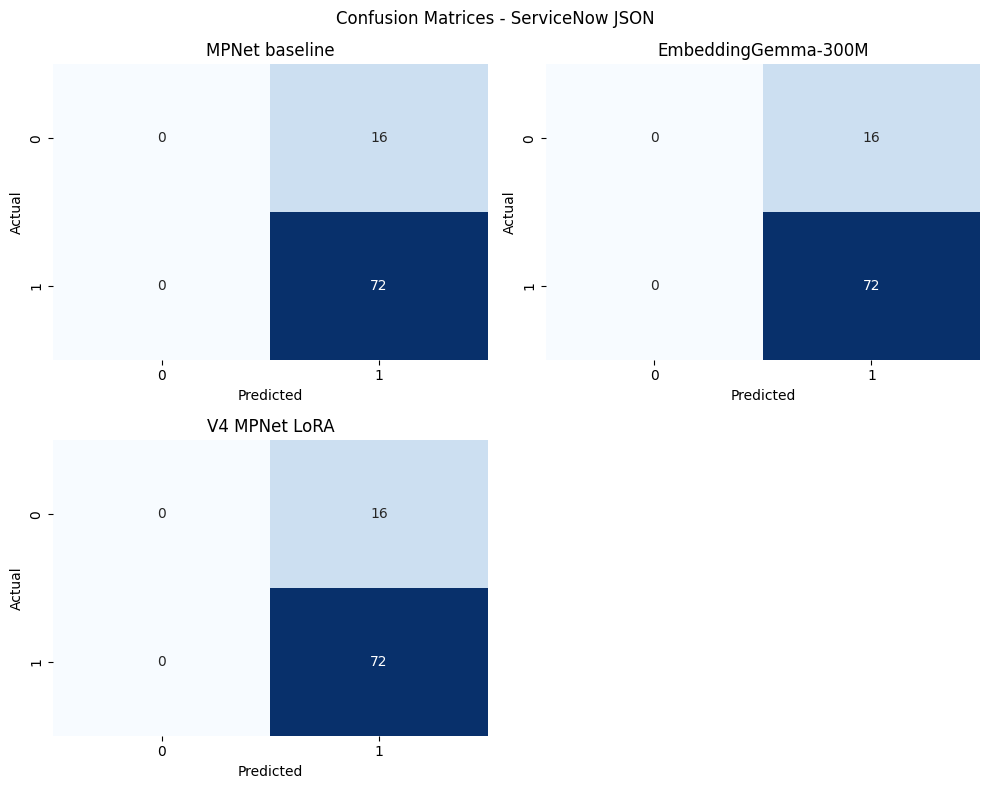

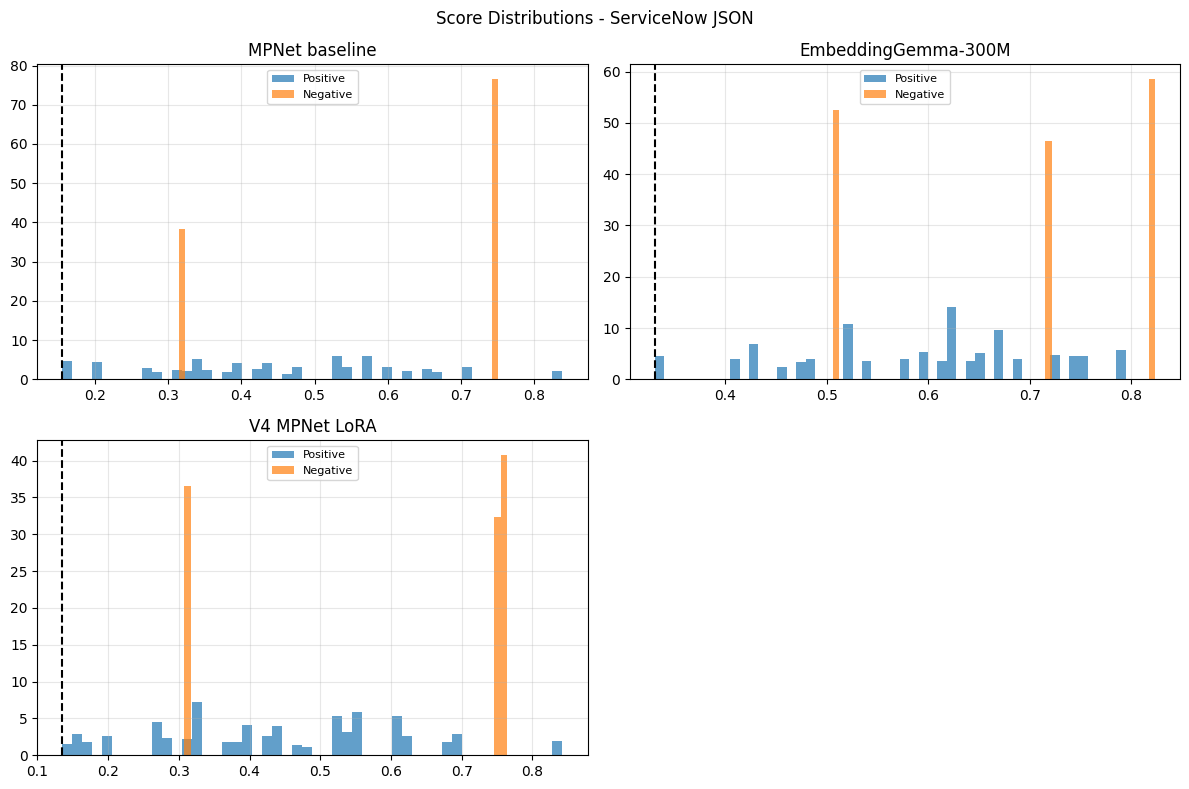

In [28]:
for dataset_name, results in results_by_dataset.items():
    if not results:
        continue
    # Confusion matrices
    ncols = min(2, len(results))
    nrows = math.ceil(len(results) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = np.atleast_1d(axes).flatten()
    for idx, (model_name, result) in enumerate(results.items()):
        ax = axes[idx]
        cm = np.array(result["metrics"]["confusion_matrix"])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{model_name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    for idx in range(len(results), len(axes)):
        axes[idx].axis("off")
    plt.suptitle(f"Confusion Matrices - {dataset_name}")
    plt.tight_layout()
    plt.show()
    # Score distributions
    ncols = min(2, len(results))
    nrows = math.ceil(len(results) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 6, nrows * 4))
    axes = np.atleast_1d(axes).flatten()
    for idx, (model_name, result) in enumerate(results.items()):
        ax = axes[idx]
        scores = result["scores"]
        labels = result["labels"]
        threshold = result["metrics"].get("val_best_threshold", result["metrics"].get("best_threshold", 0.0))
        ax.hist(scores[labels == 1], bins=50, alpha=0.7, label="Positive", density=True)
        ax.hist(scores[labels == 0], bins=50, alpha=0.7, label="Negative", density=True)
        ax.axvline(threshold, color="black", linestyle="--")
        ax.set_title(f"{model_name}")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
    for idx in range(len(results), len(axes)):
        axes[idx].axis("off")
    plt.suptitle(f"Score Distributions - {dataset_name}")
    plt.tight_layout()
    plt.show()


Clustering 800 texts for SNow CSV using MPNet baseline


Batches:   0%|          | 0/13 [00:00<?, ?it/s]

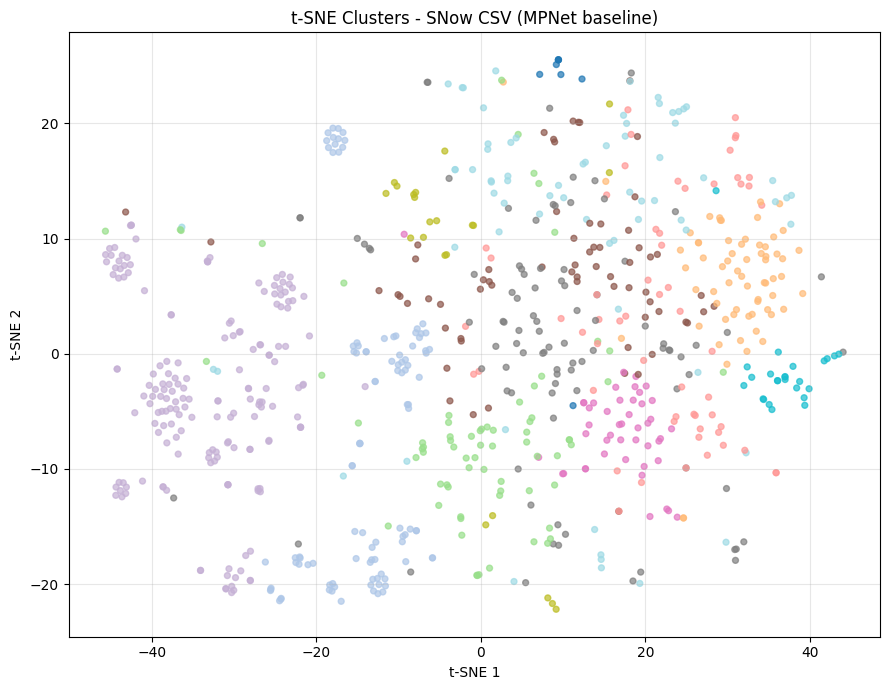

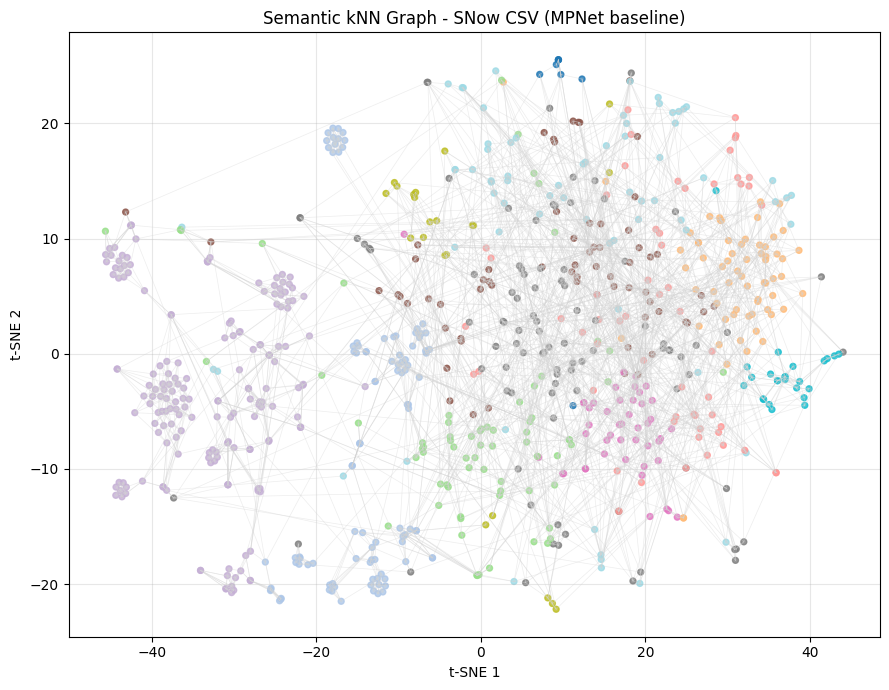

Clustering 71 texts for ServiceNow JSON using EmbeddingGemma-300M


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

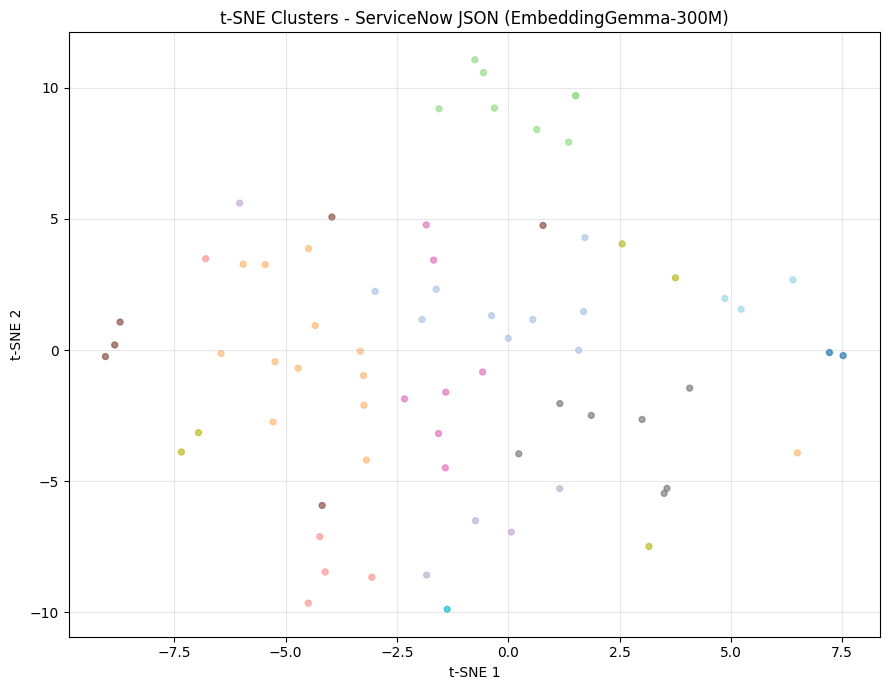

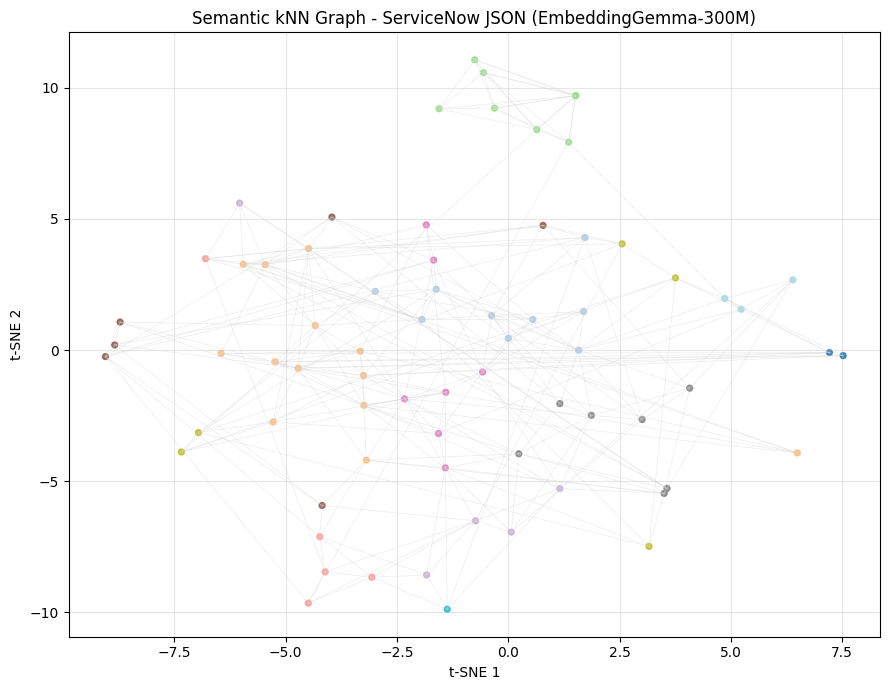

In [29]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
if CLUSTERING_ENABLED:
    for dataset_name, results in results_by_dataset.items():
        if not results:
            continue
        best_model_name = metrics_tables[dataset_name].index[0]
        best_spec = spec_by_name.get(best_model_name)
        if not best_spec:
            print(f"No model spec found for {best_model_name}")
            continue
        if best_spec["type"] == "peft" and not best_spec["model_path"].exists():
            print(f"Skipping clustering: missing model {best_spec['model_path']}")
            continue
        if best_spec["type"] == "peft":
            model = load_peft_model(best_spec["model_path"], best_spec["base_model_id"], device)
        elif best_spec["type"] == "hf":
            model = load_hf_model(best_spec["model_id"], best_spec.get("trust_remote_code", False), device)
        else:
            print(f"Skipping clustering for unsupported model: {best_model_name}")
            continue
        texts, _ = raw_texts_by_dataset[dataset_name]
        if len(texts) > CLUSTER_SAMPLE_SIZE:
            rng = np.random.default_rng(RANDOM_SEED)
            sample_idx = rng.choice(len(texts), size=CLUSTER_SAMPLE_SIZE, replace=False)
            texts = [texts[i] for i in sample_idx]
        print(f"Clustering {len(texts)} texts for {dataset_name} using {best_model_name}")
        embeddings = model.encode(texts, batch_size=batch_size, show_progress_bar=True, device=device)
        kmeans = KMeans(n_clusters=CLUSTER_N_CLUSTERS, random_state=RANDOM_SEED, n_init=10)
        labels = kmeans.fit_predict(embeddings)
        perplexity = max(5, min(30, (len(texts) - 1) // 3))
        try:
            tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=perplexity, max_iter=1000)
        except TypeError:
            tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=perplexity, n_iter=1000)
        emb_2d = tsne.fit_transform(embeddings)
        plt.figure(figsize=(9, 7))
        plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=labels, cmap="tab20", s=18, alpha=0.7)
        plt.title(f"t-SNE Clusters - {dataset_name} ({best_model_name})")
        plt.xlabel("t-SNE 1")
        plt.ylabel("t-SNE 2")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        try:
            import networkx as nx
            nbrs = NearestNeighbors(n_neighbors=min(KNN_GRAPH_K + 1, len(embeddings)), metric="cosine")
            nbrs.fit(embeddings)
            distances, indices = nbrs.kneighbors(embeddings)
            G = nx.Graph()
            for i in range(len(indices)):
                for j_idx, j in enumerate(indices[i][1:]):
                    G.add_edge(i, j, weight=1 - distances[i][j_idx + 1])
            plt.figure(figsize=(9, 7))
            for i, j in G.edges():
                plt.plot(
                    [emb_2d[i, 0], emb_2d[j, 0]],
                    [emb_2d[i, 1], emb_2d[j, 1]],
                    color="lightgray",
                    linewidth=0.5,
                    alpha=0.4,
                )
            plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=labels, cmap="tab20", s=18, alpha=0.8)
            plt.title(f"Semantic kNN Graph - {dataset_name} ({best_model_name})")
            plt.xlabel("t-SNE 1")
            plt.ylabel("t-SNE 2")
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()
        except ImportError:
            print("networkx not installed; skipping semantic graph")
        del model
        cleanup_gpu_memory(device)




In [30]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
for dataset_name, results in results_by_dataset.items():
    if not results:
        continue
    df = metrics_tables[dataset_name]
    safe_name = dataset_name.lower().replace(" ", "_")
    metrics_path = RESULTS_DIR / f"embedding_eval_{safe_name}_{timestamp}.csv"
    df.to_csv(metrics_path)
    json_path = RESULTS_DIR / f"embedding_eval_{safe_name}_{timestamp}.json"
    payload = {k: v["metrics"] for k, v in results.items()}
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2)
    print(f"Saved {dataset_name} metrics to {metrics_path}")

if CAUSAL_ENABLED:
    if not Path(CAUSAL_PAIRS_PATH).exists():
        print(f"Causal pairs not found: {CAUSAL_PAIRS_PATH}")
    elif not Path(CAUSAL_MODEL_PATH).exists():
        print(f"Causal model not found: {CAUSAL_MODEL_PATH}")
    else:
        with open(CAUSAL_PAIRS_PATH, "r", encoding="utf-8") as f:
            data = json.load(f)
        pairs = data.get("pairs", data)
        pairs = [p for p in pairs if p.get("label") in CAUSAL_LABEL_MAP]
        if CAUSAL_MAX_PAIRS and len(pairs) > CAUSAL_MAX_PAIRS:
            pairs = pairs[:CAUSAL_MAX_PAIRS]
        texts_a = [clean_text(p.get("text_a", "")) for p in pairs]
        texts_b = [clean_text(p.get("text_b", "")) for p in pairs]
        labels = np.array([CAUSAL_LABEL_MAP[p.get("label")] for p in pairs])
        split_info = stratified_split_indices(labels, VAL_RATIO, TEST_RATIO, RANDOM_SEED)
        causal_model = CrossEncoder(str(CAUSAL_MODEL_PATH), device=device)
        scores = causal_model.predict(list(zip(texts_a, texts_b)), batch_size=CAUSAL_BATCH_SIZE, show_progress_bar=True)
        scores = np.array(scores).reshape(-1)
        if len(split_info.get("val_idx", [])) and len(split_info.get("test_idx", [])):
            val_idx = split_info["val_idx"]
            test_idx = split_info["test_idx"]
            val_scores = scores[val_idx]
            val_labels = labels[val_idx]
            test_scores = scores[test_idx]
            test_labels = labels[test_idx]
            threshold, best_f1 = find_best_threshold(val_labels, val_scores)
            causal_metrics = compute_metrics(test_labels, test_scores, threshold)
            causal_metrics["val_best_threshold"] = threshold
            causal_metrics["val_best_f1"] = best_f1
            causal_metrics["val_size"] = int(len(val_idx))
            causal_metrics["test_size"] = int(len(test_idx))
            causal_metrics["confusion_matrix"] = compute_confusion(test_labels, test_scores, threshold).tolist()
        else:
            threshold, best_f1 = find_best_threshold(labels, scores)
            causal_metrics = compute_metrics(labels, scores, threshold)
            causal_metrics["best_threshold"] = threshold
            causal_metrics["best_f1"] = best_f1
            causal_metrics["val_size"] = 0
            causal_metrics["test_size"] = int(len(labels))
            causal_metrics["confusion_matrix"] = compute_confusion(labels, scores, threshold).tolist()
        causal_path = RESULTS_DIR / f"causal_eval_{timestamp}.json"
        with open(causal_path, "w", encoding="utf-8") as f:
            json.dump(causal_metrics, f, indent=2)
        print(f"Saved causal metrics to {causal_path}")


Saved SNow CSV metrics to c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results\embedding_eval_snow_csv_20260122_161500.csv
Saved ServiceNow JSON metrics to c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\results\embedding_eval_servicenow_json_20260122_161500.csv
